# Task 1: Sales Forecasting System

This notebook analyzes historical sales data and predicts future sales using machine learning.

In [4]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 2.3.3


In [5]:
df = pd.read_csv("../data/train.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9800
Number of columns: 18


In [6]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [8]:
missing_values = df.isna().sum()

missing_values[missing_values > 0]

Postal Code    11
dtype: int64

In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## Data Cleaning

### Convert the Order Date Column

The `Order Date` column is converted from text to datetime for time-based analysis.

In [12]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y"
)

print("Order Date data type:", df["Order Date"].dtype)
df[["Order Date"]].head()

Order Date data type: datetime64[ns]


,Order Date
0,2017-11-08
1,2017-11-08
2,2017-06-12
3,2016-10-11
4,2016-10-11


### Select Relevant Columns

Only the columns required for sales analysis and forecasting are retained.
Irrelevant customer, shipping, address, and identifier columns are removed.

In [13]:
columns_to_keep = [
    "Order Date",
    "Sales",
    "Category",
    "Sub-Category",
    "Region"
]

df = df[columns_to_keep].copy()

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Remaining columns:", df.columns.tolist())
print("Total missing values:", df.isna().sum().sum())

Number of rows: 9800
Number of columns: 5
Remaining columns: ['Order Date', 'Sales', 'Category', 'Sub-Category', 'Region']
Total missing values: 0


## Exploratory Data Analysis

### Monthly Sales Trend

Sales transactions are aggregated by month to analyze changes in sales over time.

In [16]:
monthly_sales = (
    df.resample("MS", on="Order Date")["Sales"]
    .sum()
    .reset_index()
)

print("First date:", df["Order Date"].min())
print("Last date:", df["Order Date"].max())
print("Number of months:", monthly_sales.shape[0])

monthly_sales.head()

First date: 2015-01-03 00:00:00
Last date: 2018-12-30 00:00:00
Number of months: 48


,Order Date,Sales
0,2015-01-01,14205.707
1,2015-02-01,4519.892
2,2015-03-01,55205.797
3,2015-04-01,27906.855
4,2015-05-01,23644.303


### Monthly Sales Line Chart

The line chart shows how total monthly sales change over time.

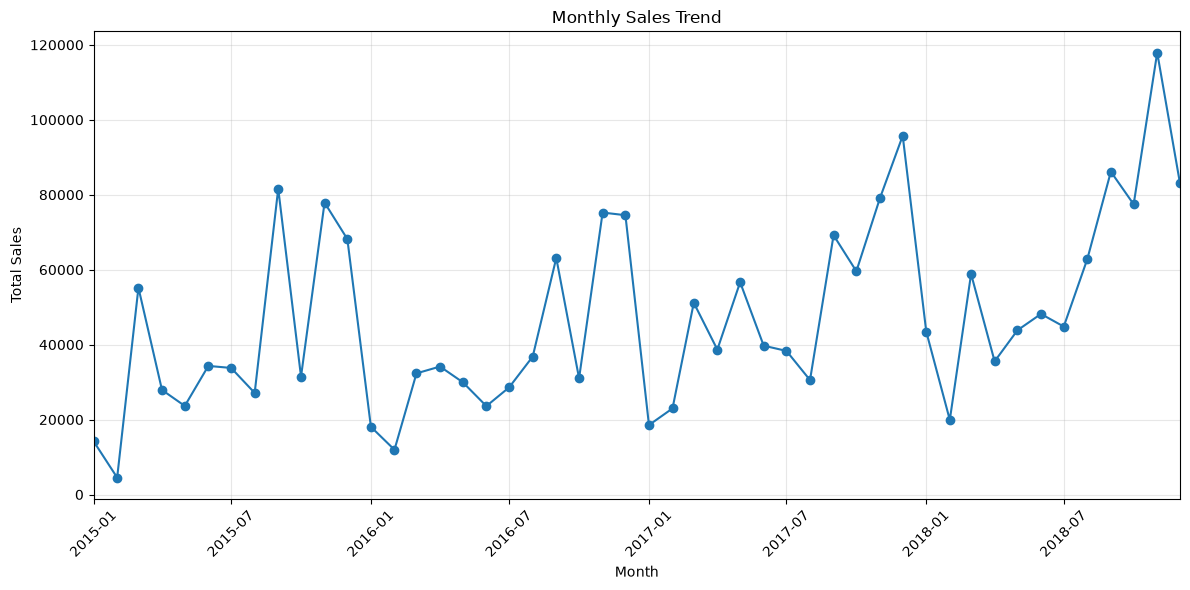

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlim(
    monthly_sales["Order Date"].min(),
    monthly_sales["Order Date"].max()
)
plt.tight_layout()
plt.show()

### Highest and Lowest Sales Months

The months with the highest and lowest total sales are identified.

In [19]:
highest_sales_month = monthly_sales.loc[
    monthly_sales["Sales"].idxmax()
]

lowest_sales_month = monthly_sales.loc[
    monthly_sales["Sales"].idxmin()
]

print(
    "Highest sales month:",
    highest_sales_month["Order Date"].strftime("%Y-%m"),
    "- Sales:",
    round(highest_sales_month["Sales"], 2)
)

print(
    "Lowest sales month:",
    lowest_sales_month["Order Date"].strftime("%Y-%m"),
    "- Sales:",
    round(lowest_sales_month["Sales"], 2)
)

Highest sales month: 2018-11 - Sales: 117938.16
Lowest sales month: 2015-02 - Sales: 4519.89


### Seasonal Sales Pattern

Average sales for each calendar month are compared to identify seasonal patterns.

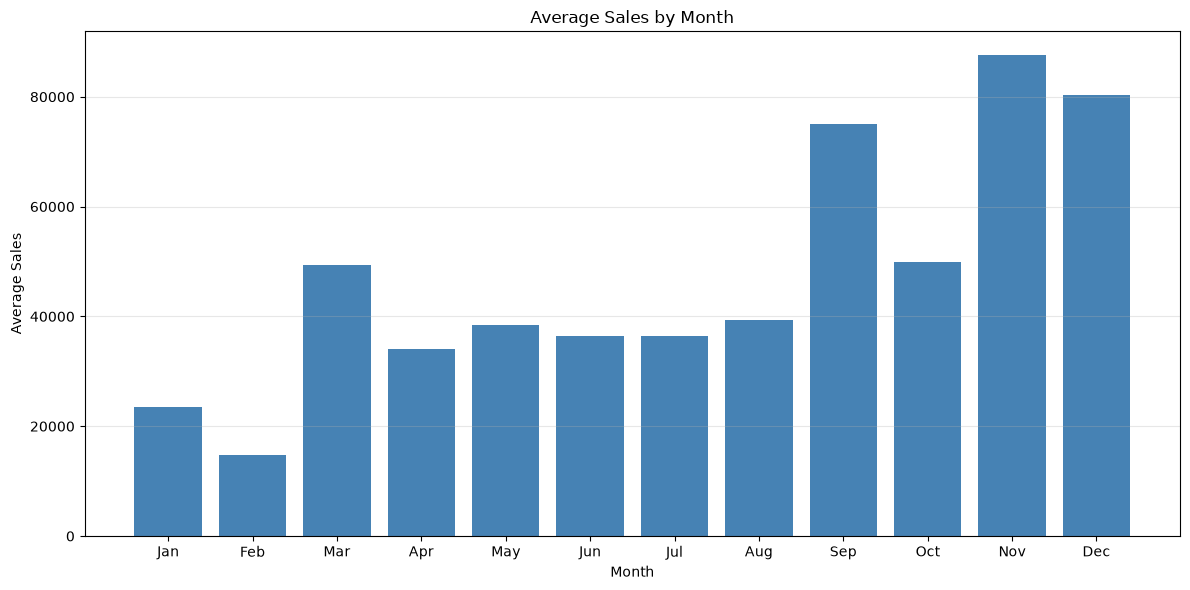

In [20]:
monthly_sales["Month Number"] = monthly_sales["Order Date"].dt.month

seasonal_sales = (
    monthly_sales.groupby("Month Number", as_index=False)["Sales"]
    .mean()
    .rename(columns={"Sales": "Average Sales"})
)

seasonal_sales["Month"] = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

plt.bar(
    seasonal_sales["Month"],
    seasonal_sales["Average Sales"],
    color="steelblue"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Sales by Season

Calendar months are grouped into four seasons based on the Northern Hemisphere.
Total and average monthly sales are calculated for each season.


In [21]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

monthly_sales["Season"] = monthly_sales["Month Number"].map(season_map)

season_summary = (
    monthly_sales.groupby("Season", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Monthly_Sales=("Sales", "mean")
    )
)

season_summary = (
    season_summary.set_index("Season")
    .loc[["Winter", "Spring", "Summer", "Autumn"]]
    .reset_index()
)

season_summary["Total_Sales"] = season_summary["Total_Sales"].round(2)
season_summary["Average_Monthly_Sales"] = (
    season_summary["Average_Monthly_Sales"].round(2)
)

season_summary

,Season,Total_Sales,Average_Monthly_Sales
0,Winter,475142.91,39595.24
1,Spring,487943.31,40661.94
2,Summer,448689.14,37390.76
3,Autumn,849761.42,70813.45


#### Seasonal Sales Bar Chart

Average monthly sales are compared across the four seasons.

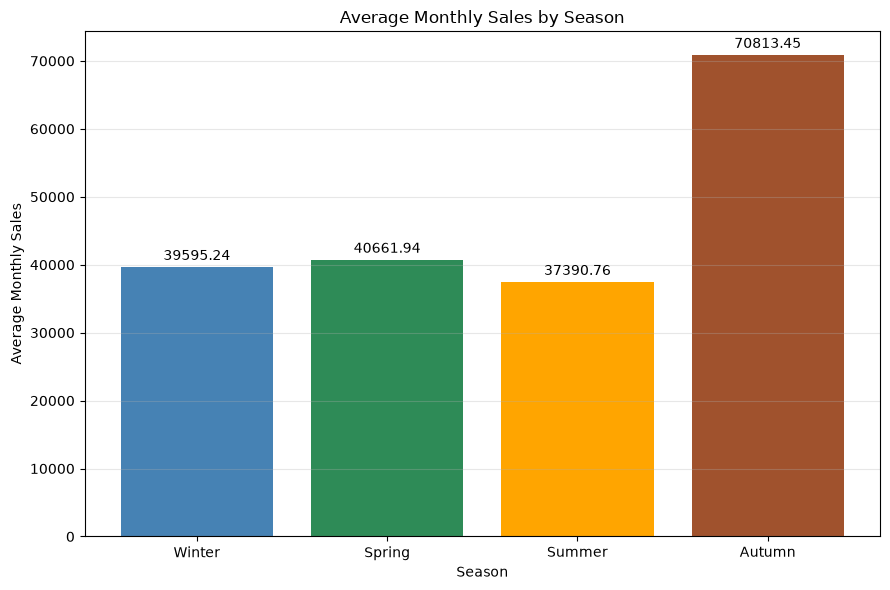

In [22]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    season_summary["Season"],
    season_summary["Average_Monthly_Sales"],
    color=["steelblue", "seagreen", "orange", "sienna"]
)

plt.title("Average Monthly Sales by Season")
plt.xlabel("Season")
plt.ylabel("Average Monthly Sales")
plt.grid(axis="y", alpha=0.3)

plt.bar_label(
    bars,
    fmt="%.2f",
    padding=3
)

plt.tight_layout()
plt.show()

### Monthly Sales Comparison by Year

Monthly sales patterns are compared across years to determine whether seasonal changes repeat consistently.

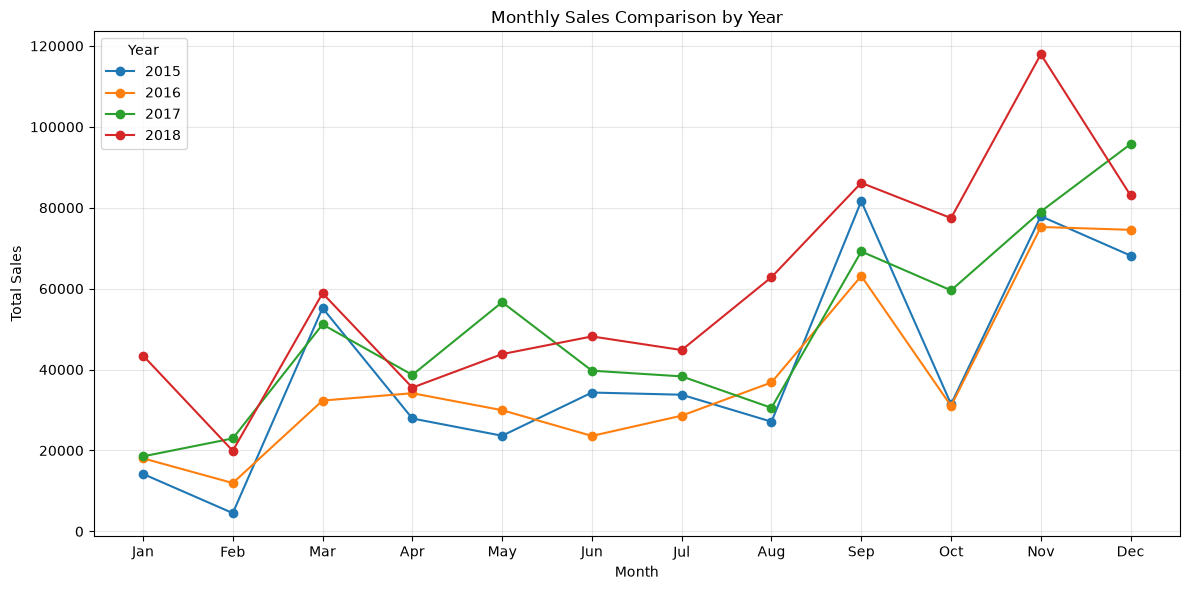

In [23]:
monthly_sales["Year"] = monthly_sales["Order Date"].dt.year

yearly_monthly_sales = monthly_sales.pivot(
    index="Month Number",
    columns="Year",
    values="Sales"
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

for year in yearly_monthly_sales.columns:
    plt.plot(
        month_names,
        yearly_monthly_sales[year],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Sales Comparison by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Seasonal Pattern Findings

- Sales generally increase in September across all years.
- A decline is observed in October.
- Sales rise strongly again in November.
- December sales generally remain high.
- Autumn has the highest average monthly sales, mainly due to strong sales in September and November.
- November 2018 shows an exceptionally high sales peak.

## Feature Engineering

### Create Daily Sales Data

Individual sales transactions are aggregated into daily total sales for model training.

In [26]:
daily_sales = (
    df.resample("D", on="Order Date")["Sales"]
    .sum()
    .reset_index()
)

print("Number of days:", daily_sales.shape[0])
print(
    "Days with zero sales:",
    (daily_sales["Sales"] == 0).sum()
)

daily_sales.sort_values(by="Sales",ascending=False).head()

Number of days: 1458
Days with zero sales: 228


,Order Date,Sales
74,2015-03-18,28106.716
1003,2017-10-02,18452.972
1388,2018-10-22,15158.877
1175,2018-03-23,14816.068
248,2015-09-08,14228.428


**Assumption:** Days without transaction records are treated as zero-sales days to create a continuous daily time series.

### Extract Date Features

Year, month, and day features are extracted from the order date for model training.

In [27]:
daily_sales["Year"] = daily_sales["Order Date"].dt.year
daily_sales["Month"] = daily_sales["Order Date"].dt.month
daily_sales["Day"] = daily_sales["Order Date"].dt.day

print("Columns:", daily_sales.columns.tolist())

daily_sales.head()

Columns: ['Order Date', 'Sales', 'Year', 'Month', 'Day']


,Order Date,Sales,Year,Month,Day
0,2015-01-03,16.448,2015,1,3
1,2015-01-04,288.060,2015,1,4
2,2015-01-05,19.536,2015,1,5
3,2015-01-06,4407.100,2015,1,6
4,2015-01-07,87.158,2015,1,7
